# Clustering Analysis on East-West Airlines Customers
### K-Means, Hierarchical and DBSCAN

**What I'm doing in this notebook:** East-West Airlines wants to know more about its frequent flyer customers (how they fly, how they earn miles, how they use the credit cards). I'll try to find customer groups (segments) using 3 clustering algorithms and then compare them.

**Plan:**
1. Load the data and clean it (missing values, outliers, scaling)
2. EDA with a bunch of plots
3. K-Means (elbow curve + silhouette)
4. Hierarchical clustering (different linkages + dendrogram)
5. DBSCAN (trying different eps and min_samples)
6. Compare everything and write what I understood from the clusters

## 0. Importing libraries

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import dendrogram, linkage

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
np.random.seed(42)

## 1. Loading the data
The excel file has 2 sheets - `Description` (just explains the columns) and `data` (the actual data). So I read the `data` sheet.

In [15]:
df = pd.read_excel('EastWestAirlines.xlsx', sheet_name='data')
print('Shape:', df.shape)
df.head()

Shape: (3999, 12)


,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,1,28143,0,1,1,1,174,1,0,0,7000,0
1,2,19244,0,1,1,1,215,2,0,0,6968,0
2,3,41354,0,1,1,1,4123,4,0,0,7034,0
3,4,14776,0,1,1,1,500,1,0,0,6952,0
4,5,97752,0,4,1,1,43300,26,2077,4,6935,1


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3999 entries, 0 to 3998
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   ID#                3999 non-null   int64
 1   Balance            3999 non-null   int64
 2   Qual_miles         3999 non-null   int64
 3   cc1_miles          3999 non-null   int64
 4   cc2_miles          3999 non-null   int64
 5   cc3_miles          3999 non-null   int64
 6   Bonus_miles        3999 non-null   int64
 7   Bonus_trans        3999 non-null   int64
 8   Flight_miles_12mo  3999 non-null   int64
 9   Flight_trans_12    3999 non-null   int64
 10  Days_since_enroll  3999 non-null   int64
 11  Award?             3999 non-null   int64
dtypes: int64(12)
memory usage: 375.0 KB


**Column meanings (from the Description sheet):**

| Column | Meaning |
|---|---|
| ID# | unique customer id (not useful for clustering) |
| Balance | miles eligible for award travel |
| Qual_miles | miles counted for Topflight status |
| cc1_miles, cc2_miles, cc3_miles | miles earned with the 3 credit cards in last 12 months, but given as **bins** 1-5 (1 = under 5,000 ... 5 = over 50,000) |
| Bonus_miles | miles from non-flight bonus transactions |
| Bonus_trans | number of non-flight bonus transactions |
| Flight_miles_12mo | flight miles in last 12 months |
| Flight_trans_12 | number of flight transactions in last 12 months |
| Days_since_enroll | days since the customer enrolled |
| Award? | 1 if the customer got an award, else 0 |

Note: cc1/cc2/cc3 are not real miles, they are categories 1 to 5, so I should remember that when reading the plots.

## 2. Data preprocessing

### 2.1 Missing values and duplicates

In [17]:
print('Missing values per column:')
print(df.isnull().sum())
print()
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate IDs :', df['ID#'].duplicated().sum())

Missing values per column:
ID#                  0
Balance              0
Qual_miles           0
cc1_miles            0
cc2_miles            0
cc3_miles            0
Bonus_miles          0
Bonus_trans          0
Flight_miles_12mo    0
Flight_trans_12      0
Days_since_enroll    0
Award?               0
dtype: int64

Duplicate rows: 0
Duplicate IDs : 0


No missing values and no duplicates, so nothing to impute or drop here. The `ID#` column is just an identifier, so I'm dropping it because it has no meaning for clustering (it would only add noise).

In [18]:
data = df.drop(columns=['ID#'])
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Balance,3999.0,73601.327582,100775.664958,0.0,18527.5,43097.0,92404.0,1704838.0
Qual_miles,3999.0,144.114529,773.663804,0.0,0.0,0.0,0.0,11148.0
cc1_miles,3999.0,2.059515,1.376919,1.0,1.0,1.0,3.0,5.0
cc2_miles,3999.0,1.014504,0.147650,1.0,1.0,1.0,1.0,3.0
cc3_miles,3999.0,1.012253,0.195241,1.0,1.0,1.0,1.0,5.0
Bonus_miles,3999.0,17144.846212,24150.967826,0.0,1250.0,7171.0,23800.5,263685.0
Bonus_trans,3999.0,11.601900,9.603810,0.0,3.0,12.0,17.0,86.0
Flight_miles_12mo,3999.0,460.055764,1400.209171,0.0,0.0,0.0,311.0,30817.0
Flight_trans_12,3999.0,1.373593,3.793172,0.0,0.0,0.0,1.0,53.0
Days_since_enroll,3999.0,4118.559390,2065.134540,2.0,2330.0,4096.0,5790.5,8296.0


Looking at the describe table, the columns are super skewed. For example `Balance` has a mean of ~73k but max of 1.7 million, and `Qual_miles` is 0 for more than 75% of customers. So outliers are going to be a problem. Let me look at boxplots first.

### 2.2 Outliers

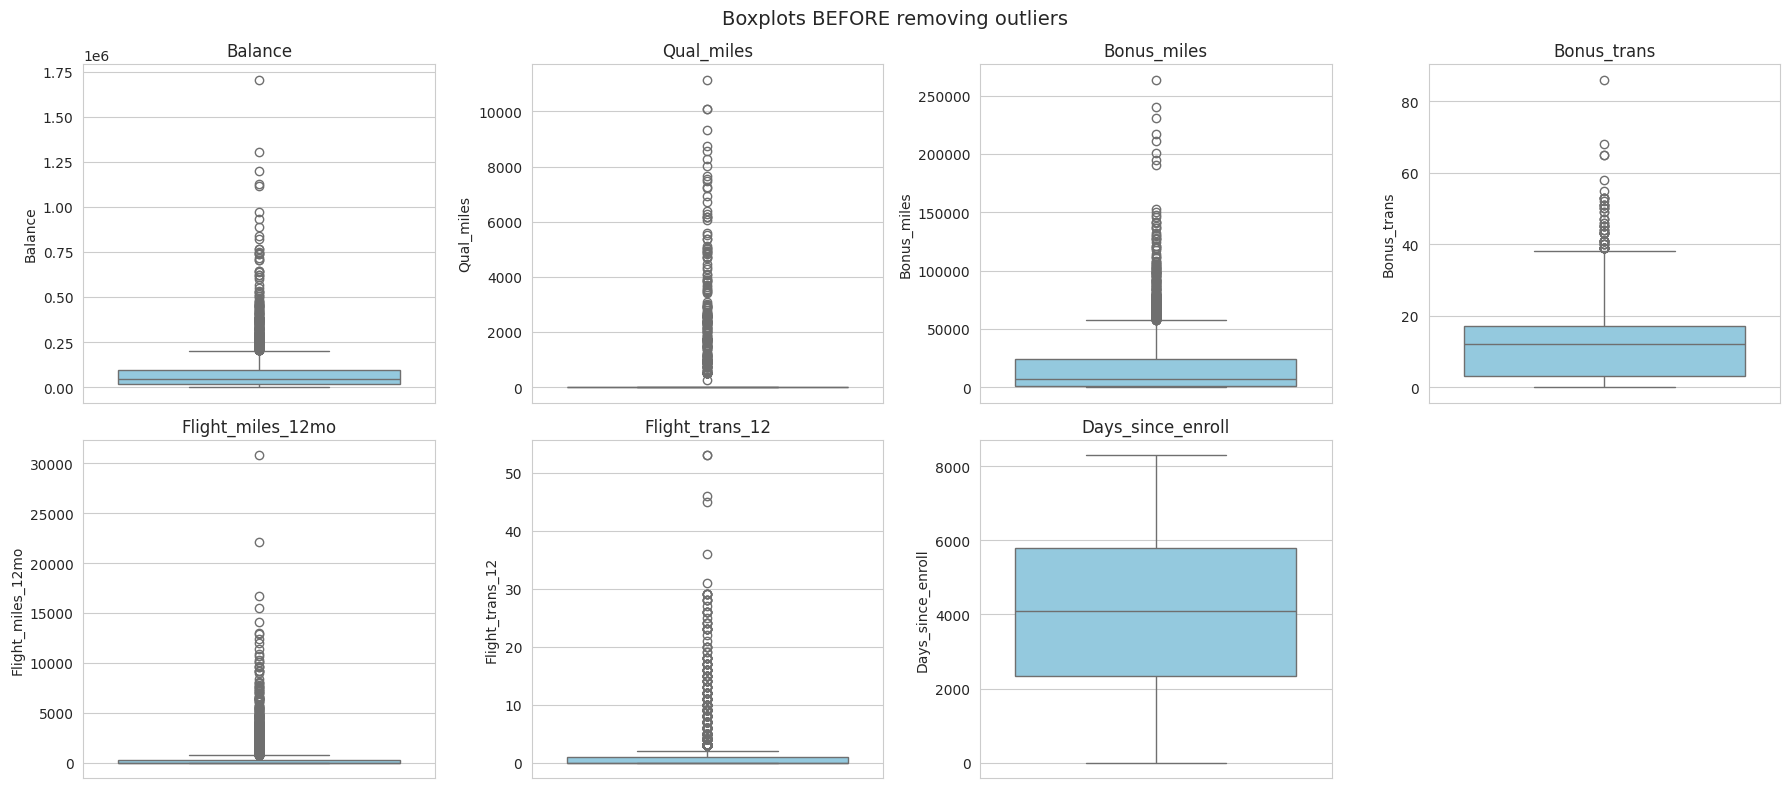

In [19]:
num_cols = ['Balance', 'Qual_miles', 'Bonus_miles', 'Bonus_trans',
            'Flight_miles_12mo', 'Flight_trans_12', 'Days_since_enroll']

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, c in enumerate(num_cols):
    sns.boxplot(y=data[c], ax=axes[i], color='skyblue')
    axes[i].set_title(c)
axes[-1].axis('off')
plt.suptitle('Boxplots BEFORE removing outliers', fontsize=14)
plt.tight_layout()
plt.show()

Lots of points way above the whiskers. I first thought of using the normal IQR rule (1.5*IQR) but that doesn't work well here, because for `Qual_miles` and the flight columns the 25th and 75th percentile are both 0 or very close, so IQR = 0 and the rule would delete every customer who ever flew or earned qualifying miles - and those are exactly the interesting customers.

So I'm using the **z-score method** instead: remove a row if any numeric column is more than 4 standard deviations from the mean. Let me check how many rows go away for different cutoffs first.

In [20]:
z = ((data[num_cols] - data[num_cols].mean()) / data[num_cols].std()).abs()

for cutoff in [3, 4, 5]:
    print(f'z > {cutoff}: {(z > cutoff).any(axis=1).sum()} rows would be removed')

z > 3: 321 rows would be removed
z > 4: 184 rows would be removed
z > 5: 125 rows would be removed


In [21]:
# going with 4, it removes less than 5% of rows
mask = ~(z > 4).any(axis=1)
data_clean = data[mask].reset_index(drop=True)

print('Rows before:', len(data))
print('Rows after :', len(data_clean))
print(f'Removed    : {len(data) - len(data_clean)} rows ({(len(data) - len(data_clean)) / len(data) * 100:.1f}%)')

Rows before: 3999
Rows after : 3815
Removed    : 184 rows (4.6%)


### 2.3 Feature scaling

The columns are on totally different scales (Balance is in the 10,000s, cc2_miles is 1 to 3). K-Means, hierarchical and DBSCAN all use distances, so the big columns would take over everything. I'm using `StandardScaler` (mean 0, std 1) to fix this.

In [22]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(data_clean)
X_scaled_df = pd.DataFrame(X_scaled, columns=data_clean.columns)

print('Means after scaling (should be ~0):', X_scaled_df.mean().round(2).values)
print('Stds  after scaling (should be ~1):', X_scaled_df.std().round(2).values)

Means after scaling (should be ~0): [ 0. -0.  0.  0. -0. -0.  0.  0. -0.  0. -0.]
Stds  after scaling (should be ~1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 3. Exploratory Data Analysis (EDA)

### 3.1 Distribution of the features

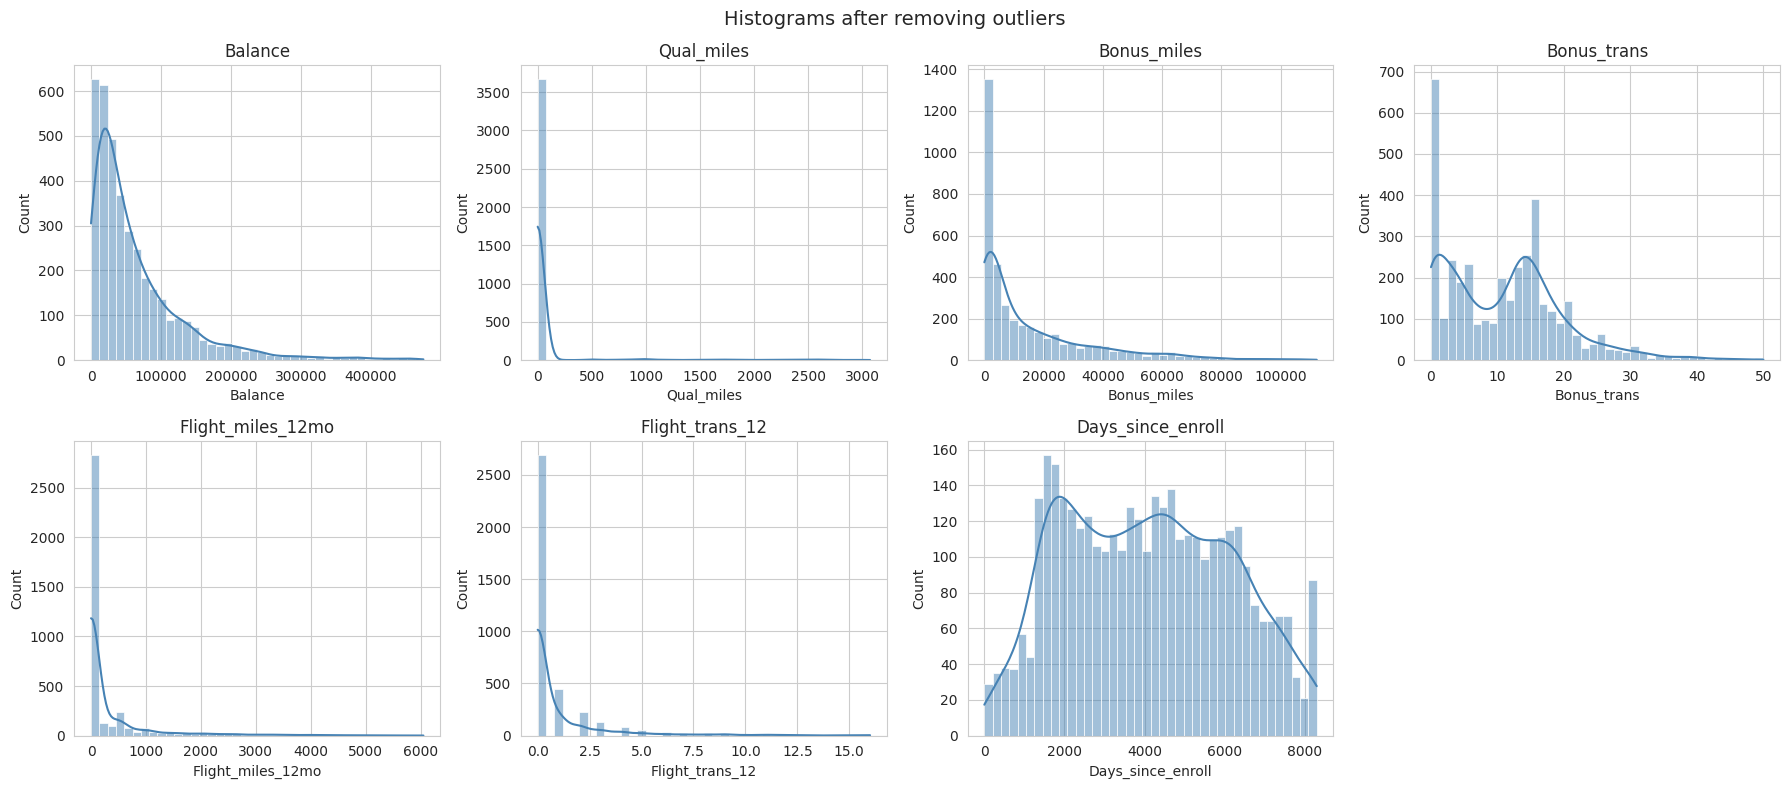

In [23]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, c in enumerate(num_cols):
    sns.histplot(data_clean[c], bins=40, kde=True, ax=axes[i], color='steelblue')
    axes[i].set_title(c)
axes[-1].axis('off')
plt.suptitle('Histograms after removing outliers', fontsize=14)
plt.tight_layout()
plt.show()

**What I see:**
- Almost all the columns are still right skewed even after removing outliers (skewness of `Qual_miles` is about 6, `Flight_miles_12mo` and `Flight_trans_12` about 3.5, `Balance` about 2.3).
- `Qual_miles` is 0 for 96% of the customers and `Flight_miles_12mo` is 0 for around 71%. So most members hardly fly with the airline at all, which is interesting.
- `Bonus_trans` looks the closest to a normal shape and `Days_since_enroll` is spread out almost evenly, so there are both old and new members.
- So the data is mostly a big group of low-activity customers plus a long tail of very active ones.

### 3.2 Categorical-type columns (credit card bins and Award)

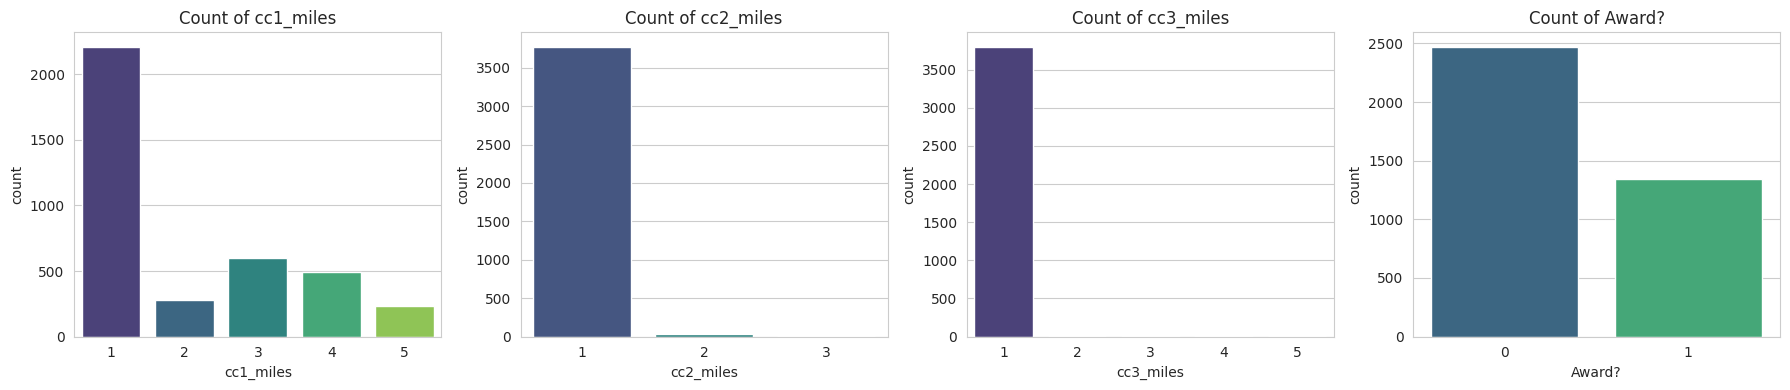

Award rate: 0.352


In [24]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, ['cc1_miles', 'cc2_miles', 'cc3_miles', 'Award?']):
    sns.countplot(x=data_clean[c], ax=ax, palette='viridis')
    ax.set_title(f'Count of {c}')
plt.tight_layout()
plt.show()

print('Award rate:', data_clean['Award?'].mean().round(3))

**What I see:**
- `cc2_miles` and `cc3_miles` are 1 for around 99% of the customers, so nearly nobody earns miles with the Rewards or Small Business card. These two columns won't really help in separating groups.
- `cc1_miles` has more variety, but still about 58% are in bin 1 (under 5,000 miles), and a smaller group is in the higher bins.
- Around 35% of the customers have got an award, 65% have not.

### 3.3 Correlation heatmap

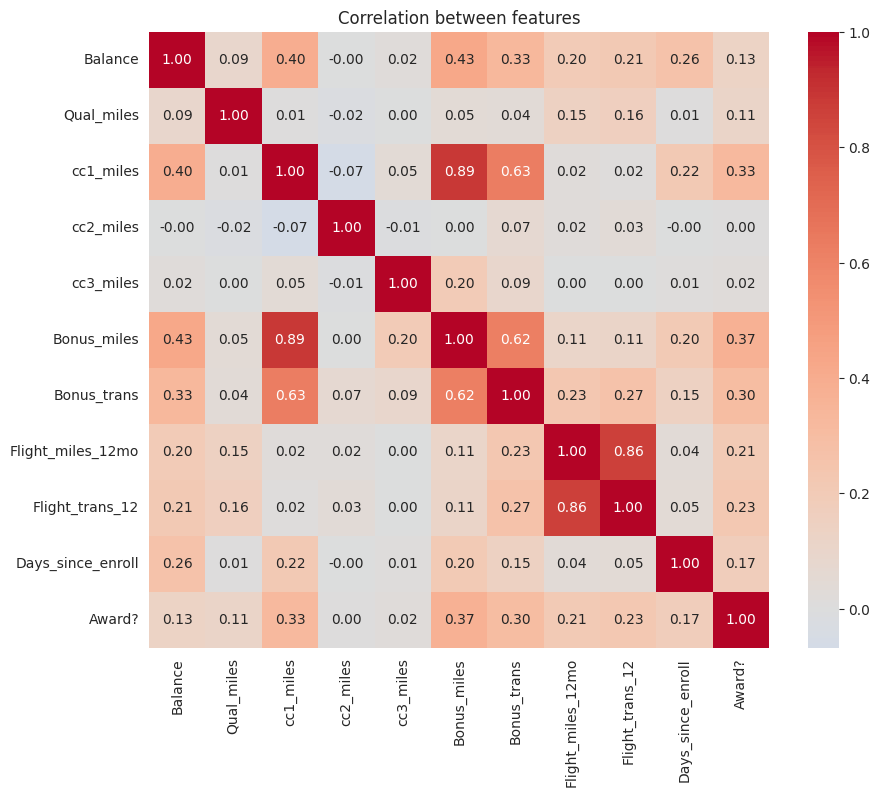

In [25]:
plt.figure(figsize=(10, 8))
sns.heatmap(data_clean.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation between features')
plt.show()

**What I see:**
- `Flight_miles_12mo` and `Flight_trans_12` are strongly correlated (0.86), which makes sense, more flights = more flight miles.
- `cc1_miles` and `Bonus_miles` are also strongly correlated (0.89), I think because miles earned using the credit card also show up as bonus miles. `Bonus_miles` and `Bonus_trans` have 0.62.
- `Balance` is related more to `Bonus_miles` (0.43) and `cc1_miles` (0.40) than to flight miles (0.20). So customers mostly collect their miles through credit card / bonus transactions, not by flying.
- `Qual_miles` has weak correlation with everything.
- No pair is so correlated (like 0.95+) that I need to drop a column, so I'm keeping all of them.

### 3.4 Looking for possible clusters with scatter plots

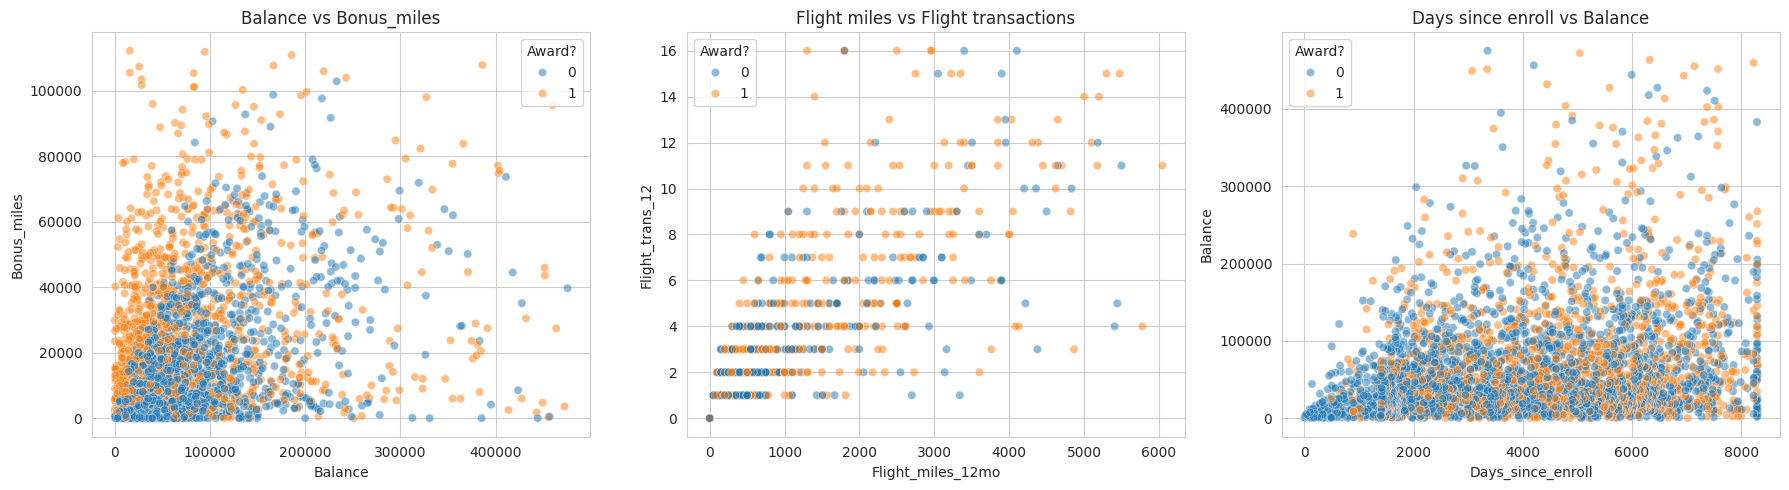

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=data_clean, x='Balance', y='Bonus_miles', hue='Award?', alpha=0.5, ax=axes[0])
axes[0].set_title('Balance vs Bonus_miles')

sns.scatterplot(data=data_clean, x='Flight_miles_12mo', y='Flight_trans_12', hue='Award?', alpha=0.5, ax=axes[1])
axes[1].set_title('Flight miles vs Flight transactions')

sns.scatterplot(data=data_clean, x='Days_since_enroll', y='Balance', hue='Award?', alpha=0.5, ax=axes[2])
axes[2].set_title('Days since enroll vs Balance')

plt.tight_layout()
plt.show()

**What I see:**
- There is no clear separate blobs. It is mostly one dense group near the lower left (low balance, low bonus miles, no flights) with a long tail going out.
- In the flight miles vs flight transactions plot, a huge number of points are stuck at (0, 0), and the rest are on a roughly straight line.
- Customers with `Award? = 1` (orange) are more towards the higher balance / bonus miles side, but they are still mixed with the others.
- Because of this I don't expect super well separated clusters, so the silhouette scores will probably be low-ish.

### 3.5 Pairplot of the main features

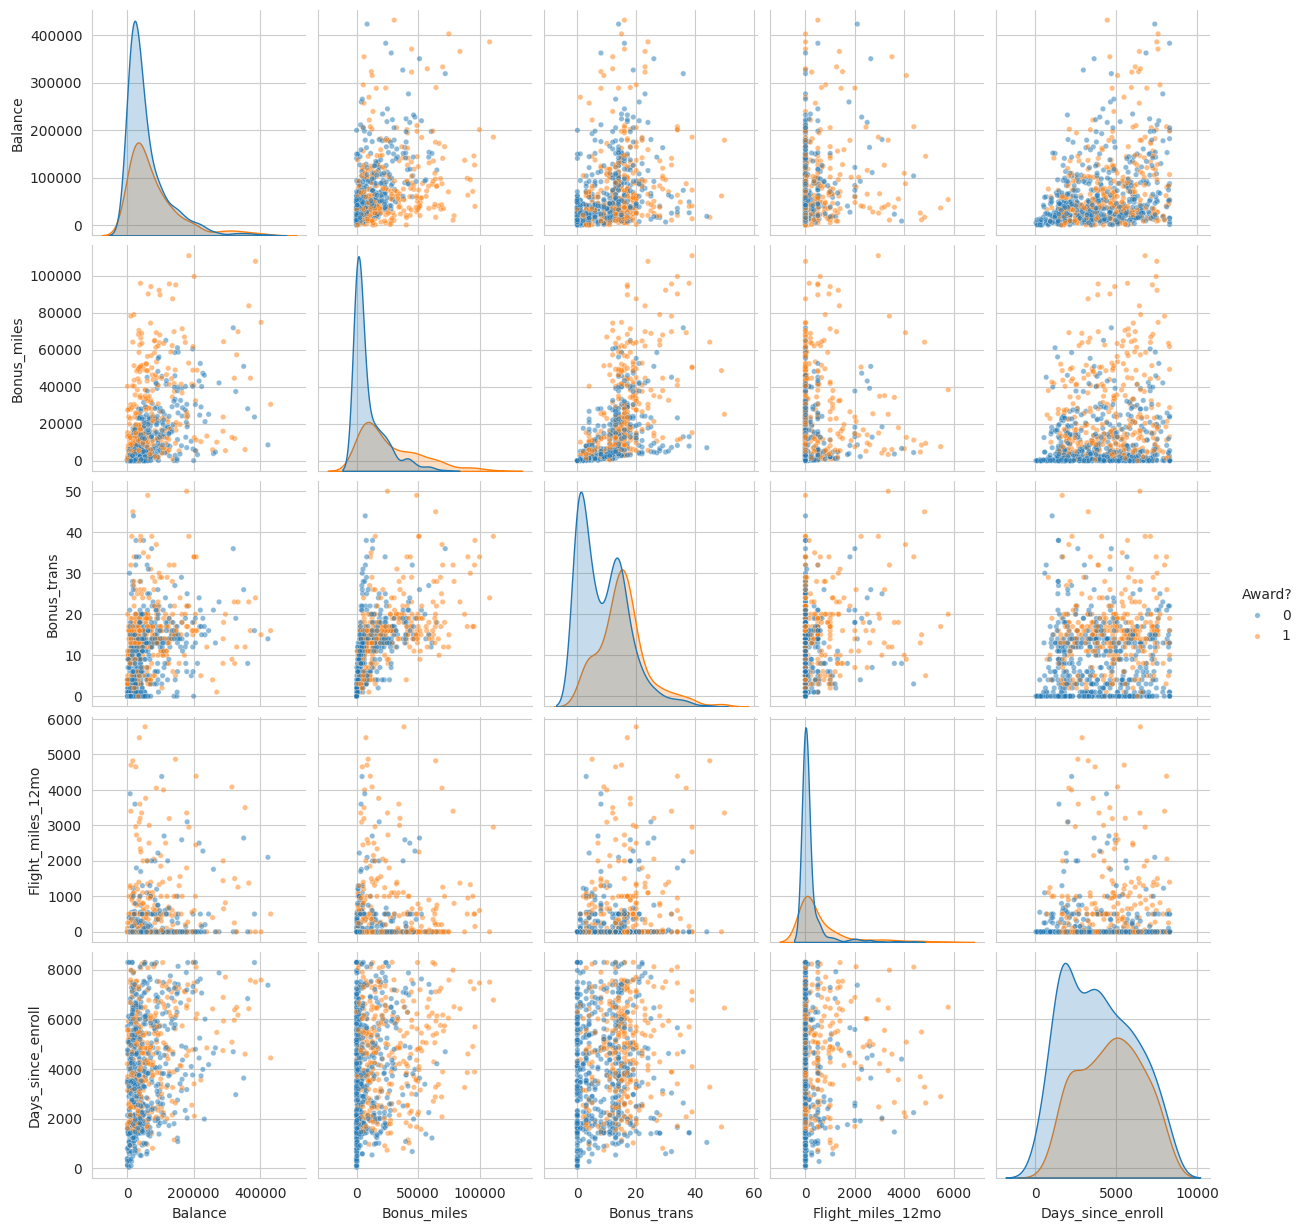

In [27]:
# using a sample of 800 rows otherwise the pairplot is slow
sample = data_clean.sample(800, random_state=42)
sns.pairplot(sample[['Balance', 'Bonus_miles', 'Bonus_trans', 'Flight_miles_12mo', 'Days_since_enroll', 'Award?']],
             hue='Award?', plot_kws={'alpha': 0.5, 's': 15}, diag_kind='kde')
plt.show()

**What I see:** Same story as before. The diagonal (kde) plots are all skewed with a peak near zero, and the scatter plots don't show clean islands of points. The `Award? = 1` customers generally have higher `Bonus_miles` and `Bonus_trans`, so the Award column might have an effect on the clustering later (I'll keep an eye on it in DBSCAN).

### 3.6 Reducing to 2D with PCA (only for plotting)

I can't plot 10 dimensions, so I use PCA to squeeze the scaled data into 2 components. **Important:** the clustering is done on the full scaled data, PCA is just so I can draw the clusters on a 2D plot.

Variance explained by PC1, PC2: [0.289 0.167]
Total: 0.455


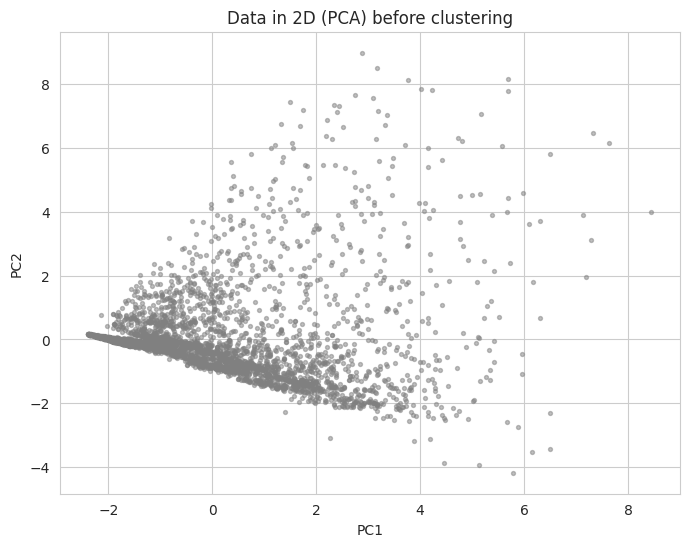

In [28]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print('Variance explained by PC1, PC2:', pca.explained_variance_ratio_.round(3))
print('Total:', pca.explained_variance_ratio_.sum().round(3))

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], s=8, alpha=0.5, color='gray')
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.title('Data in 2D (PCA) before clustering')
plt.show()

**What I see:** PC1 and PC2 together explain only about 45% of the variance, so this 2D picture is losing a lot of information and clusters that look overlapped here may be better separated in the real 10 dimensions. Still, it looks like one big cloud shaped like a wedge, with a sparse tail of very active customers. No obvious gaps, so the clusters will probably touch each other.

## 4. K-Means Clustering

### 4.1 Choosing K - Elbow curve and silhouette score

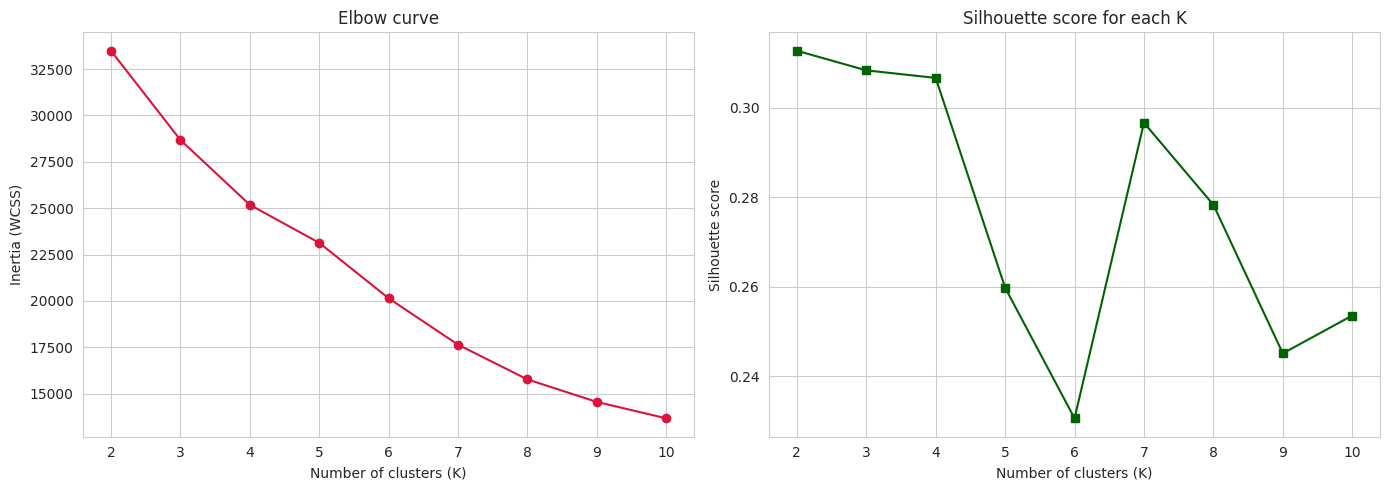

,K,Inertia,Silhouette
0,2,33486.0,0.313
1,3,28681.8,0.308
2,4,25183.0,0.307
3,5,23135.2,0.260
4,6,20148.6,0.231
5,7,17644.1,0.297
6,8,15773.3,0.278
7,9,14560.4,0.245
8,10,13676.4,0.254


In [29]:
k_range = range(2, 11)
inertias = []
sil_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(k_range), inertias, 'o-', color='crimson')
axes[0].set_xlabel('Number of clusters (K)')
axes[0].set_ylabel('Inertia (WCSS)')
axes[0].set_title('Elbow curve')

axes[1].plot(list(k_range), sil_scores, 's-', color='darkgreen')
axes[1].set_xlabel('Number of clusters (K)')
axes[1].set_ylabel('Silhouette score')
axes[1].set_title('Silhouette score for each K')

plt.tight_layout()
plt.show()

pd.DataFrame({'K': list(k_range), 'Inertia': np.round(inertias, 1), 'Silhouette': np.round(sil_scores, 3)})

**How I chose K:**
- The elbow curve goes down smoothly and there isn't a really sharp elbow. There is a small bend around K = 3 to 4.
- The silhouette score is highest at K = 2 (0.313) but K = 3 (0.308) and K = 4 (0.307) are almost the same. After K = 4 it drops a lot (K = 5, 6 are bad), and there is a small bump at K = 7 but that doesn't help much.
- K = 2 is too simple (just "active" vs "not active"). When I tried K = 4 one cluster had only 12 customers, which is not a useful segment.
- So I'm going with **K = 3**, it is a good balance between the elbow, the silhouette score and being easy to explain.

In [30]:
K_FINAL = 3

kmeans = KMeans(n_clusters=K_FINAL, n_init=10, random_state=42)
km_labels = kmeans.fit_predict(X_scaled)

km_sil = silhouette_score(X_scaled, km_labels)
print('K-Means with K =', K_FINAL)
print('Silhouette score:', round(km_sil, 4))
print('Cluster sizes:')
print(pd.Series(km_labels).value_counts().sort_index())

K-Means with K = 3
Silhouette score: 0.3083
Cluster sizes:
0    2363
1     262
2    1190
Name: count, dtype: int64


### 4.2 K-Means cluster visualization

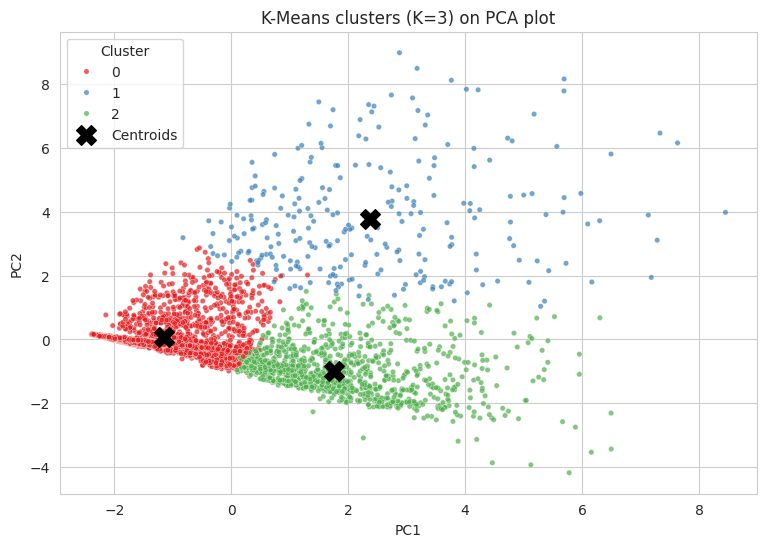

In [31]:
plt.figure(figsize=(9, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=km_labels, palette='Set1', s=15, alpha=0.7, legend='full')
centers_pca = pca.transform(kmeans.cluster_centers_)
plt.scatter(centers_pca[:, 0], centers_pca[:, 1], c='black', marker='X', s=200, label='Centroids')
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.title(f'K-Means clusters (K={K_FINAL}) on PCA plot')
plt.legend(title='Cluster')
plt.show()

### 4.3 Understanding the K-Means clusters

In [32]:
data_clean['KMeans'] = km_labels

profile_cols = list(data.columns)
km_profile = data_clean.groupby('KMeans')[profile_cols].mean().round(1)
km_profile['Size'] = data_clean['KMeans'].value_counts().sort_index()
km_profile

,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?,Size
KMeans,,,,,,,,,,,,
0,40124.0,43.6,1.2,1.0,1.0,4247.3,6.6,106.4,0.4,3688.5,0.2,2363
1,107150.3,282.1,1.9,1.0,1.0,19819.5,17.7,2610.4,7.5,4276.4,0.7,262
2,103975.8,43.9,3.7,1.0,1.0,36780.0,18.1,183.8,0.6,4821.0,0.6,1190


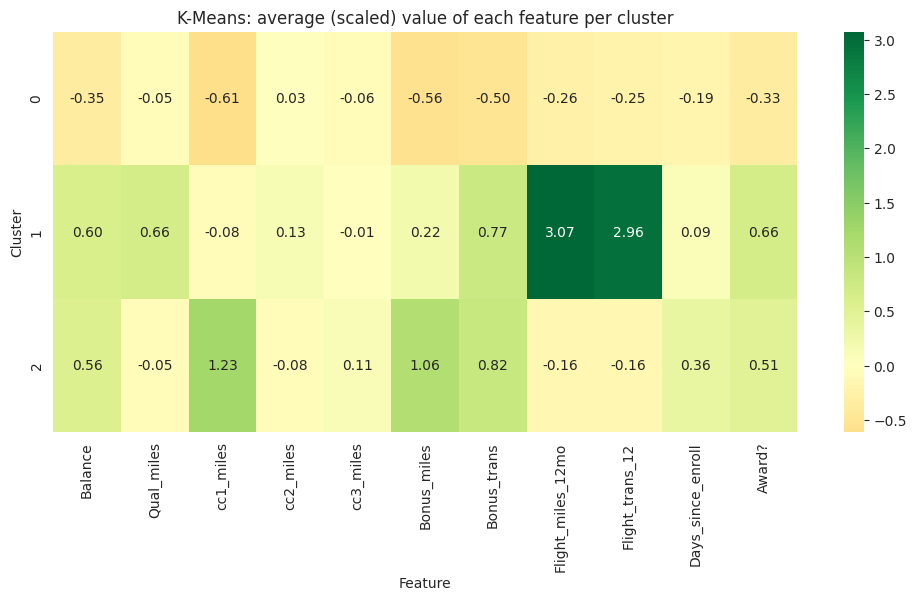

In [33]:
# heatmap of the cluster means (scaled so all columns can be compared)
km_means_scaled = pd.DataFrame(X_scaled_df.groupby(km_labels).mean().values,
                               columns=profile_cols)
plt.figure(figsize=(12, 4 + 0.4 * K_FINAL))
sns.heatmap(km_means_scaled, annot=True, fmt='.2f', cmap='RdYlGn', center=0)
plt.xlabel('Feature'); plt.ylabel('Cluster')
plt.title('K-Means: average (scaled) value of each feature per cluster')
plt.show()

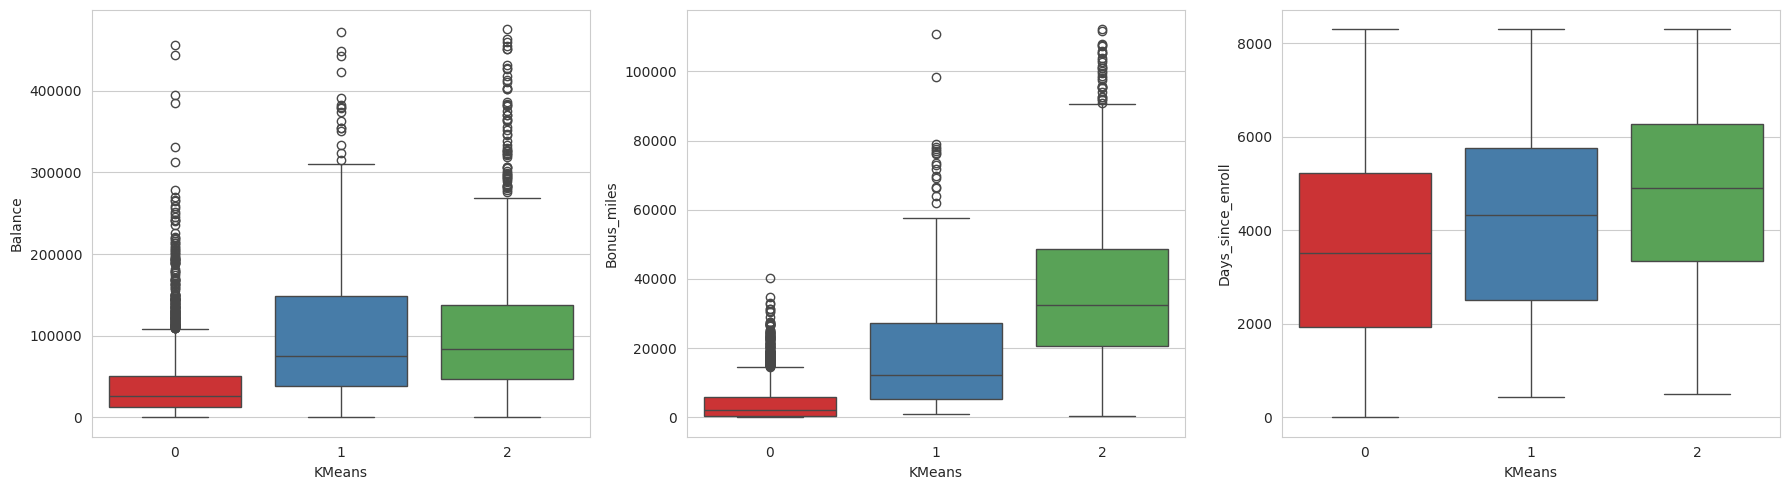

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(x='KMeans', y='Balance', data=data_clean, palette='Set1', ax=axes[0])
sns.boxplot(x='KMeans', y='Bonus_miles', data=data_clean, palette='Set1', ax=axes[1])
sns.boxplot(x='KMeans', y='Days_since_enroll', data=data_clean, palette='Set1', ax=axes[2])
plt.tight_layout()
plt.show()

**K-Means cluster interpretation (K = 3):**

| Cluster | Size | What they look like | My name for it |
|---|---|---|---|
| 0 | 2363 (~62%) | Lowest balance (~40k), very few bonus miles (~4k), almost no flights (0.4 per year), credit card bin ~1.2, only ~20% got an award, newest members | **Low activity / casual members** |
| 1 | 262 (~7%) | Very high flight miles (~2600), ~7.5 flight transactions, highest `Qual_miles` (~280), high balance (~107k), 67% got an award | **Frequent flyers** |
| 2 | 1190 (~31%) | High balance (~104k), highest bonus miles (~37k), credit card bin ~3.7, but almost no flying (~184 flight miles), oldest members (~4800 days), 59% got an award | **Credit card / bonus miles earners** |

**Insights:**
- The 3 groups are different in *how* they earn miles, not only how much. Cluster 1 earns by flying, cluster 2 earns by spending on the credit card and bonus partners.
- Cluster 2 customers are loyal (long time members) but they don't fly much, so the airline could try offers to make them fly more (use their big balance).
- Cluster 1 is small but is the most valuable for the airline's actual flight revenue, so it should be taken care of (Topflight status benefits, upgrades).
- Cluster 0 is more than half of the customers and they are barely active. The airline could try to wake them up with credit card offers or small promos.
- Silhouette is 0.308, which means the clusters are there but overlap a lot, as I guessed from the EDA.

## 5. Hierarchical Clustering

### 5.1 Dendrogram (Ward linkage)

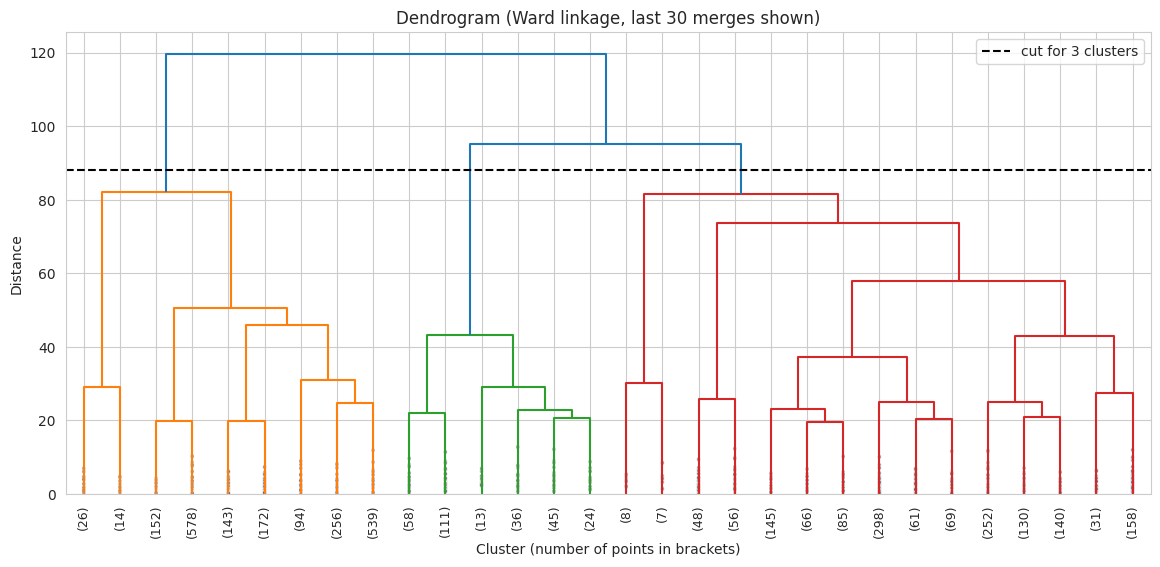

In [35]:
Z = linkage(X_scaled, method='ward')

plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=9, show_contracted=True)
plt.axhline(88, color='black', linestyle='--', label='cut for 3 clusters')
plt.legend()
plt.title('Dendrogram (Ward linkage, last 30 merges shown)')
plt.xlabel('Cluster (number of points in brackets)')
plt.ylabel('Distance')
plt.show()

**Reading the dendrogram:** The last merges happen at big distances (around 95 and 120 on the y-axis). If I cut the tree at around 88 (red dashed line) I get 3 branches (orange, green and red), and these branches only join much higher up. So the dendrogram also supports using **3 clusters**, which matches what I got from K-Means.

### 5.2 Trying different linkage criteria

In [36]:
rows = []
for link in ['ward', 'complete', 'average', 'single']:
    for n in [3, 4, 5, 6]:
        lab = AgglomerativeClustering(n_clusters=n, linkage=link).fit_predict(X_scaled)
        rows.append({'Linkage': link,
                     'Clusters': n,
                     'Silhouette': round(silhouette_score(X_scaled, lab), 3),
                     'Smallest cluster size': np.bincount(lab).min(),
                     'Largest cluster size': np.bincount(lab).max()})
link_results = pd.DataFrame(rows)
link_results

,Linkage,Clusters,Silhouette,Smallest cluster size,Largest cluster size
0,ward,3,0.258,287,1974
1,ward,4,0.269,40,1934
2,ward,5,0.273,15,1934
3,ward,6,0.286,15,1934
4,complete,3,0.623,8,3767
5,complete,4,0.621,7,3760
6,complete,5,0.471,7,3644
7,complete,6,0.480,7,3525
8,average,3,0.676,2,3801
9,average,4,0.619,2,3761


**Comparing linkages:**
- `complete`, `average` and `single` give very high silhouette scores (0.5 to 0.68), which looks great at first, **but** look at the cluster sizes: the biggest cluster has 3700+ customers out of 3815 and the smallest ones have only 1 to 8 customers. So these methods just pick a few extreme customers and put them in their own tiny clusters, and everyone else is in one giant cluster. The high silhouette is misleading here, and this is not a useful segmentation.
- `ward` has a lower silhouette (about 0.26 to 0.29) but its clusters are much more balanced, because it tries to minimize the variance inside clusters (the same idea as K-Means).
- So I'm using **Ward linkage with 3 clusters** (also matches the dendrogram).

In [37]:
N_CLUSTERS_HC = 3

hc = AgglomerativeClustering(n_clusters=N_CLUSTERS_HC, linkage='ward')
hc_labels = hc.fit_predict(X_scaled)

hc_sil = silhouette_score(X_scaled, hc_labels)
print('Hierarchical (ward), clusters =', N_CLUSTERS_HC)
print('Silhouette score:', round(hc_sil, 4))
print(pd.Series(hc_labels).value_counts().sort_index())

Hierarchical (ward), clusters = 3
Silhouette score: 0.2583
0    1974
1    1554
2     287
Name: count, dtype: int64


### 5.3 Hierarchical cluster visualization

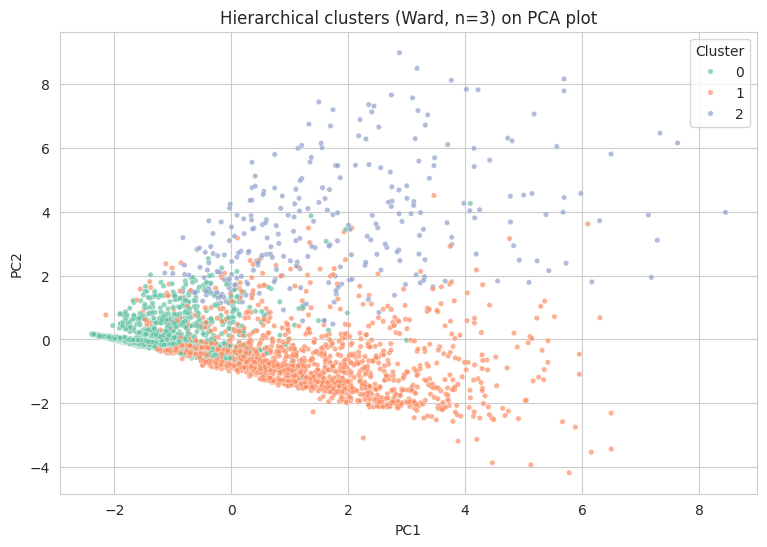

In [38]:
plt.figure(figsize=(9, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=hc_labels, palette='Set2', s=15, alpha=0.7, legend='full')
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.title(f'Hierarchical clusters (Ward, n={N_CLUSTERS_HC}) on PCA plot')
plt.legend(title='Cluster')
plt.show()

### 5.4 Understanding the hierarchical clusters

In [39]:
data_clean['Hierarchical'] = hc_labels

hc_profile = data_clean.groupby('Hierarchical')[profile_cols].mean().round(1)
hc_profile['Size'] = data_clean['Hierarchical'].value_counts().sort_index()
hc_profile

,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?,Size
Hierarchical,,,,,,,,,,,,
0,40253.8,0.6,1.1,1.0,1.0,3236.2,5.5,84.2,0.3,3800.0,0.2,1974
1,90225.6,119.2,3.3,1.0,1.0,30954.0,17.2,198.0,0.6,4432.6,0.5,1554
2,93889.0,148.8,1.7,1.0,1.0,15702.6,14.8,2370.3,6.9,4125.0,0.7,287


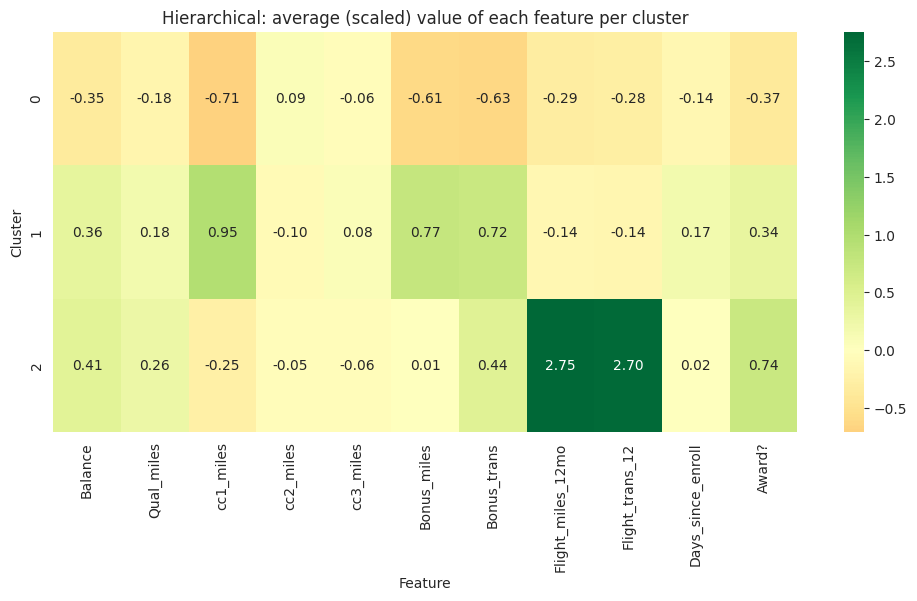

In [40]:
hc_means_scaled = pd.DataFrame(X_scaled_df.groupby(hc_labels).mean().values,
                               columns=profile_cols)
plt.figure(figsize=(12, 4 + 0.4 * N_CLUSTERS_HC))
sns.heatmap(hc_means_scaled, annot=True, fmt='.2f', cmap='RdYlGn', center=0)
plt.xlabel('Feature'); plt.ylabel('Cluster')
plt.title('Hierarchical: average (scaled) value of each feature per cluster')
plt.show()

**Hierarchical (Ward) cluster interpretation:**

| Cluster | Size | What they look like | Similar to K-Means |
|---|---|---|---|
| 0 | 1974 (~52%) | Balance ~40k, bonus miles ~3k, almost no flights, award rate ~20% | Cluster 0 (low activity) |
| 1 | 1554 (~41%) | Balance ~90k, bonus miles ~31k, credit card bin ~3.3, hardly any flights | Cluster 2 (card / bonus earners) |
| 2 | 287 (~7.5%) | Flight miles ~2370, ~7 flight transactions, balance ~94k, award rate ~70% | Cluster 1 (frequent flyers) |

**Insights:**
- Hierarchical clustering found the same 3 types of customers as K-Means (casual, card earners, frequent flyers), which makes me more confident that these segments are real.
- The difference is in the boundaries. Ward put more customers (1554) in the card earner group than K-Means (1190), so the "medium" customers are being split in a different place.
- The silhouette score (0.258) is lower than K-Means (0.308).
- One negative thing is that hierarchical clustering is slow for big data, it was fine here with only ~3800 rows.

## 6. DBSCAN

DBSCAN needs two parameters: `eps` (radius of the neighbourhood) and `min_samples` (minPts, the minimum points needed in the radius to make a core point). I don't want to just guess so I'll use a k-distance plot to get an idea for eps, and then try a grid of values.

### 6.1 k-distance plot to pick eps

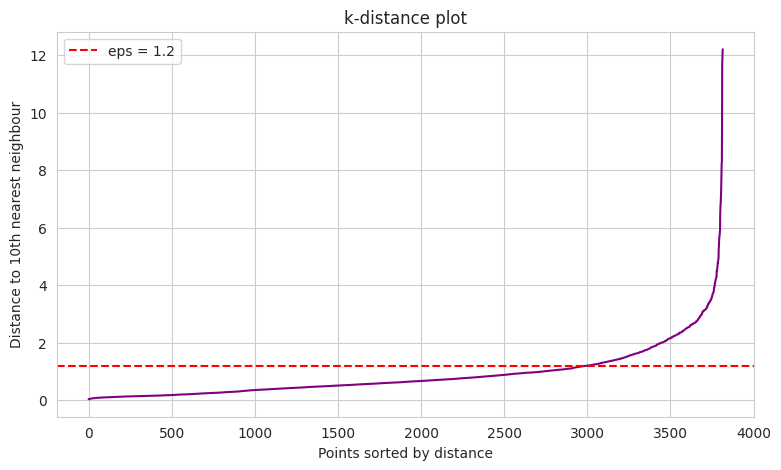

In [41]:
k = 10   # looking at the distance to the 10th nearest neighbour
nn = NearestNeighbors(n_neighbors=k).fit(X_scaled)
distances, _ = nn.kneighbors(X_scaled)
k_dist = np.sort(distances[:, -1])

plt.figure(figsize=(9, 5))
plt.plot(k_dist, color='purple')
plt.axhline(1.2, color='red', linestyle='--', label='eps = 1.2')
plt.xlabel('Points sorted by distance')
plt.ylabel(f'Distance to {k}th nearest neighbour')
plt.title('k-distance plot')
plt.legend()
plt.show()

**Reading the plot:** The curve is almost flat up to around 3000 points and after that it starts going up fast. The "knee" is around a distance of 1.2 to 1.5, so I started with eps = 1.2 (red line). Points on the steep right part are far away from everything else, these will become noise. I'll check with the grid below instead of trusting only this plot.

### 6.2 Grid search over eps and min_samples

In [42]:
rows = []
for eps in [0.6, 0.8, 1.0, 1.2, 1.5, 2.0]:
    for ms in [5, 10, 15, 20]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        n_clusters = len(set(lab)) - (1 if -1 in lab else 0)
        n_noise = (lab == -1).sum()
        if n_clusters > 1:
            sil = round(silhouette_score(X_scaled[lab != -1], lab[lab != -1]), 3)
        else:
            sil = np.nan
        rows.append({'eps': eps, 'min_samples': ms, 'clusters': n_clusters,
                     'noise points': n_noise, 'noise %': round(n_noise / len(lab) * 100, 1),
                     'silhouette (no noise)': sil})
db_results = pd.DataFrame(rows)
db_results

,eps,min_samples,clusters,noise points,noise %,silhouette (no noise)
0,0.6,5,21,1316,34.5,0.120
1,0.6,10,8,1618,42.4,0.185
2,0.6,15,9,1793,47.0,0.178
3,0.6,20,6,1961,51.4,0.208
4,0.8,5,10,901,23.6,0.202
5,0.8,10,5,1124,29.5,0.147
6,0.8,15,2,1278,33.5,0.337
7,0.8,20,2,1347,35.3,0.341
8,1.0,5,5,637,16.7,0.275
9,1.0,10,2,760,19.9,0.302


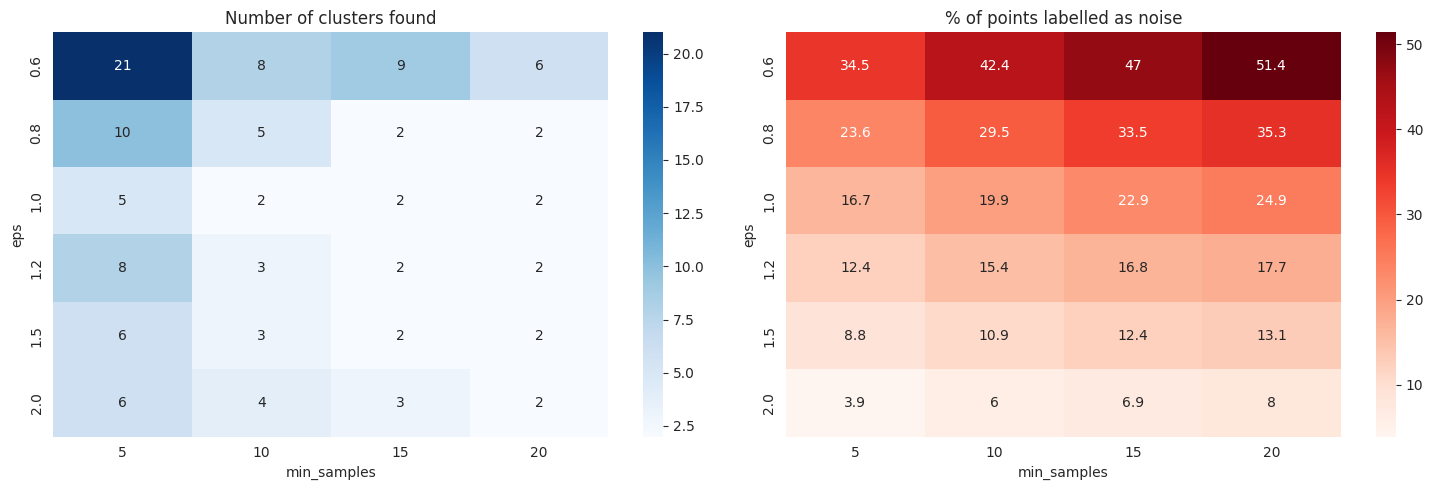

In [43]:
# heatmaps to see the effect of the parameters quickly
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(db_results.pivot(index='eps', columns='min_samples', values='clusters'),
            annot=True, fmt='g', cmap='Blues', ax=axes[0])
axes[0].set_title('Number of clusters found')
sns.heatmap(db_results.pivot(index='eps', columns='min_samples', values='noise %'),
            annot=True, fmt='g', cmap='Reds', ax=axes[1])
axes[1].set_title('% of points labelled as noise')
plt.tight_layout()
plt.show()

**What happens when I change the parameters:**
- With a small eps (0.6, 0.8) there are lots of small clusters and about 24% to 51% of the data is noise. This is too strict.
- With a big eps (2.0) the noise is small (4% to 8%) but the clusters start merging together.
- If I increase min_samples, noise increases and the number of clusters goes down.
- Some settings have a nicer silhouette (0.30 to 0.34) but they only find 2 clusters and throw away 20% to 35% of customers as noise, so that is not really better.
- I'm choosing **eps = 1.2 and min_samples = 10**: 3 clusters, 15.4% noise and a silhouette of 0.29. It's a good middle point.

In [44]:
EPS = 1.2
MIN_SAMPLES = 10

db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES)
db_labels = db.fit_predict(X_scaled)

n_clusters_db = len(set(db_labels)) - (1 if -1 in db_labels else 0)
mask_db = db_labels != -1
db_sil = silhouette_score(X_scaled[mask_db], db_labels[mask_db])

print(f'DBSCAN eps={EPS}, min_samples={MIN_SAMPLES}')
print('Clusters found:', n_clusters_db)
print('Noise points  :', (~mask_db).sum(), f'({(~mask_db).mean() * 100:.1f}%)')
print('Silhouette score (noise excluded):', round(db_sil, 4))
print(pd.Series(db_labels).value_counts().sort_index())

DBSCAN eps=1.2, min_samples=10
Clusters found: 3
Noise points  : 588 (15.4%)
Silhouette score (noise excluded): 0.2923
-1     588
 0    2248
 1     969
 2      10
Name: count, dtype: int64


### 6.3 DBSCAN visualization

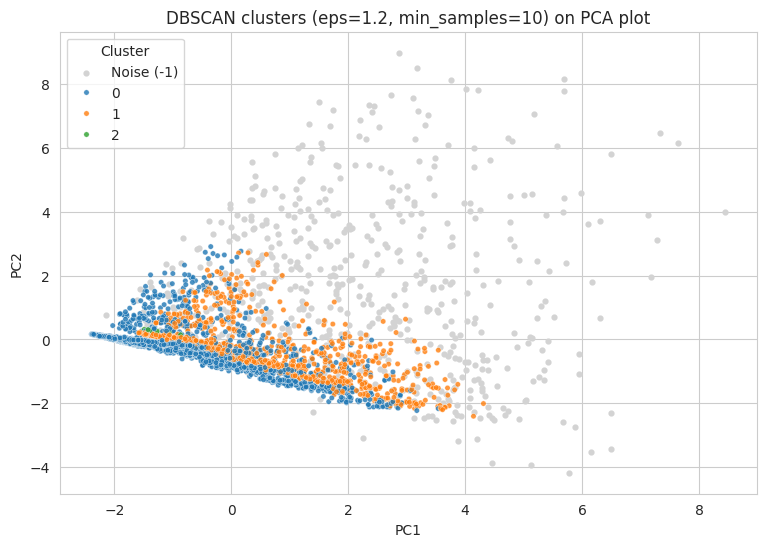

In [45]:
plt.figure(figsize=(9, 6))
plt.scatter(X_pca[~mask_db, 0], X_pca[~mask_db, 1], c='lightgray', s=12, label='Noise (-1)')
sns.scatterplot(x=X_pca[mask_db, 0], y=X_pca[mask_db, 1], hue=db_labels[mask_db],
                palette='tab10', s=15, alpha=0.8, legend='full')
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.title(f'DBSCAN clusters (eps={EPS}, min_samples={MIN_SAMPLES}) on PCA plot')
plt.legend(title='Cluster')
plt.show()

### 6.4 Understanding the DBSCAN clusters

In [46]:
data_clean['DBSCAN'] = db_labels

db_profile = data_clean.groupby('DBSCAN')[profile_cols].mean().round(1)
db_profile['Size'] = data_clean['DBSCAN'].value_counts().sort_index()
db_profile   # cluster -1 is the noise group

,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?,Size
DBSCAN,,,,,,,,,,,,
-1,129756.5,389.6,2.5,1.1,1.1,29606.9,18.2,1369.3,4.1,4580.2,0.6,588
0,51895.6,0.0,1.7,1.0,1.0,8918.0,8.3,85.1,0.3,3798.9,0.0,2248
1,55093.6,0.0,2.6,1.0,1.0,22142.5,12.6,162.5,0.6,4449.0,1.0,969
2,27372.7,0.0,1.0,2.0,1.0,8459.1,11.7,0.0,0.0,2919.1,0.0,10


**DBSCAN interpretation:**

| Cluster | Size | What they look like |
|---|---|---|
| -1 (noise) | 588 (15.4%) | Highest balance (~130k), highest `Qual_miles` (~390), lots of flights (flight miles ~1370, ~4 trans), 60% awards. Basically the extreme / heavy users |
| 0 | 2248 | **Everyone has Award = 0**, low balance (~52k), low bonus miles (~9k), almost no flights |
| 1 | 969 | **Everyone has Award = 1**, balance ~55k, bonus miles ~22k, higher credit card bin |
| 2 | 10 | Tiny group, the only one using the 2nd credit card (cc2 bin = 2), no flights at all, newest members |

**Insights:**
- DBSCAN mostly split the customers using the `Award?` column. This is because it's a 0/1 column, so after scaling the distance between award and non-award customers is about 2 in this one column, bigger than eps = 1.2, so the points can't connect across. So the clusters are basically "no award" vs "got an award".
- The very active customers (frequent flyers, high balance) are spread out and not dense, so DBSCAN calls them noise instead of making a cluster. That's actually a weakness for this dataset, because these are probably the customers the airline cares about most. But it is also useful as an outlier detector.
- Cluster 2 (10 customers) is too small to matter much, but it shows there is a small group using the Rewards credit card.
- The silhouette (0.292) is calculated **without** the noise points, so it is not exactly fair to compare with K-Means.

## 7. Comparing the three algorithms

In [47]:
comparison = pd.DataFrame({
    'Algorithm': ['K-Means', 'Hierarchical (Ward)', 'DBSCAN'],
    'Clusters': [K_FINAL, N_CLUSTERS_HC, n_clusters_db],
    'Noise points': [0, 0, int((~mask_db).sum())],
    'Silhouette score': [round(km_sil, 3), round(hc_sil, 3), round(db_sil, 3)]
})
comparison

,Algorithm,Clusters,Noise points,Silhouette score
0,K-Means,3,0,0.308
1,Hierarchical (Ward),3,0,0.258
2,DBSCAN,3,588,0.292


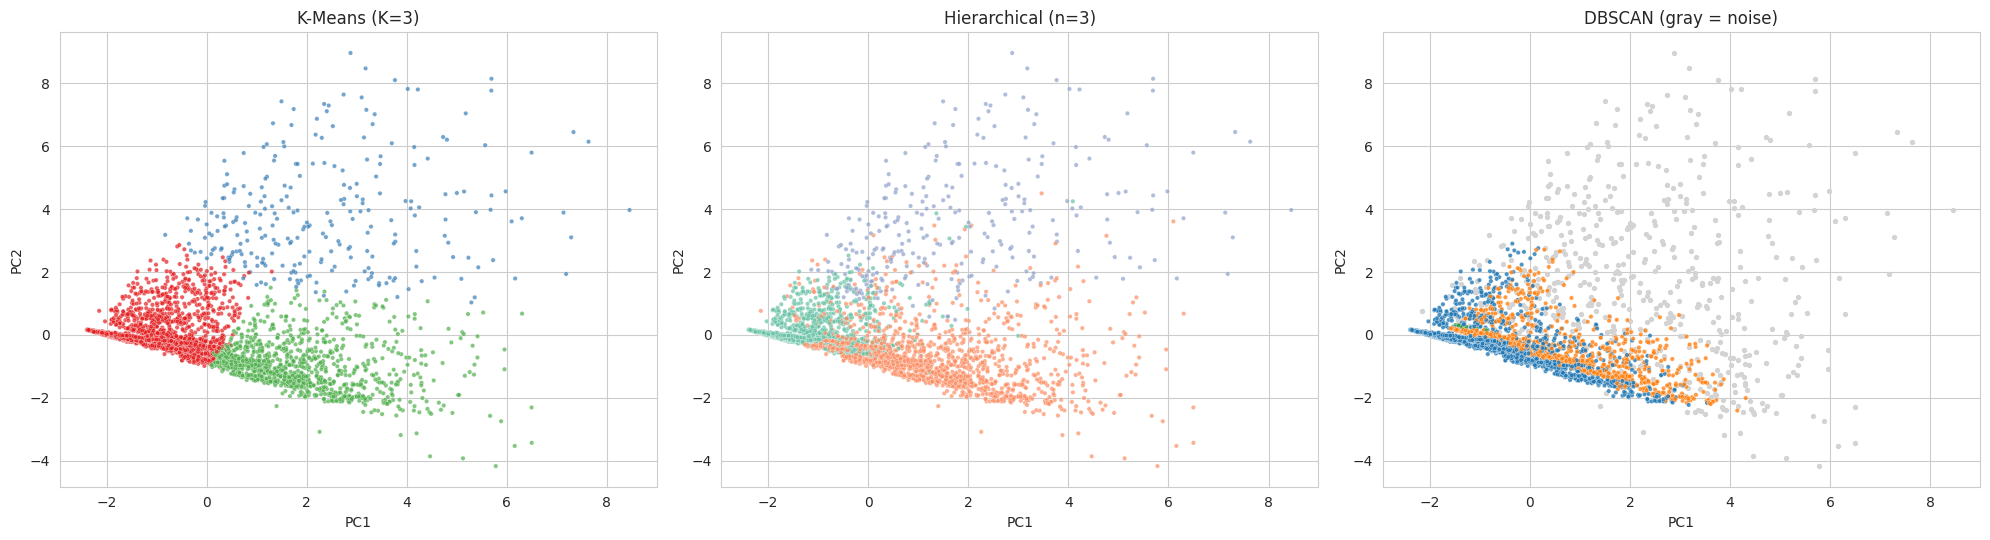

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=km_labels, palette='Set1', s=10, alpha=0.7, ax=axes[0], legend=False)
axes[0].set_title(f'K-Means (K={K_FINAL})')

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=hc_labels, palette='Set2', s=10, alpha=0.7, ax=axes[1], legend=False)
axes[1].set_title(f'Hierarchical (n={N_CLUSTERS_HC})')

axes[2].scatter(X_pca[~mask_db, 0], X_pca[~mask_db, 1], c='lightgray', s=8)
sns.scatterplot(x=X_pca[mask_db, 0], y=X_pca[mask_db, 1], hue=db_labels[mask_db], palette='tab10', s=10, alpha=0.8, ax=axes[2], legend=False)
axes[2].set_title('DBSCAN (gray = noise)')

for ax in axes:
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
plt.tight_layout()
plt.show()

**Comparison:**
- All three silhouette scores are between 0.26 and 0.31. That is a weak to moderate structure (below 0.5), so the customer groups overlap and the data is more like one continuous cloud than separate islands.
- **K-Means** has the best silhouette (0.308), gives non-overlapping clusters that cover every customer, and the clusters are easy to explain.
- **Hierarchical (Ward)** found almost the same 3 customer types, so it agrees with K-Means. It has the lowest silhouette (0.258), and the dendrogram is useful to see the structure.
- **DBSCAN** found something different (split by award, with the heavy users as noise). Its silhouette (0.292) ignores 15% of the points so it can't be compared directly.
- For a marketing team who wants segments to send offers to, I think **K-Means with K = 3** is the best choice here.

## 8. Final insights and conclusion

### Final summary

**Customer segments found (K-Means and Hierarchical agree on these):**
1. **Low activity members (about 50 to 60% of customers):** small balance, few bonus miles, hardly fly, low award rate.
2. **Credit card / bonus miles earners (about 30 to 40%):** big balance mostly from credit card and bonus miles, old members, but don't fly much.
3. **Frequent flyers (about 7%):** lots of flight miles and flight transactions, highest qualifying miles, high award rate.

**What the airline could do:**
- Frequent flyers: protect them with premium benefits, upgrades, Topflight status.
- Card earners: they have many miles stored but don't use the airline, so give them offers or promotions to redeem miles and fly more.
- Low activity members: this is the biggest group, so small promotions or credit card sign-up offers could make a big difference.

**What I learned about the methods:**
- Scaling was really important, and the z-score method worked better than the IQR method for removing outliers on this skewed data.
- The silhouette score alone can fool you (the complete / average / single linkages had high scores but with useless clusters), so I had to look at the cluster sizes too.
- DBSCAN is very sensitive to eps and min_samples, and a binary column can control the whole result.

**Limitations / what I would try next:**
- The data is very skewed, so I could try a log transform before scaling.
- `cc1/cc2/cc3_miles` are bins (categories) and `Award?` is 0/1, so treating them as normal numbers is not perfect. I could try without `Award?` or use a method like K-Prototypes.
- Silhouette scores are low overall (about 0.3), so the segments are not sharply separated, the labels I gave are just a simple way to describe them.